In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from data_analysis.config import load_config
from data_analysis.loaders.heroin import load_heroin
from data_analysis.loaders.rat_reward import load_rat_reward
from data_analysis.loaders.human_cud import load_human_cud

In [4]:
cfg = load_config()
heroin = load_heroin(cfg)
rat = load_rat_reward(cfg)
human = load_human_cud(cfg)

GSE174737_Male_Morphine_Nromalized.txt.gz: data rows repeat t_name; dropped the extra column


In [4]:
pd.crosstab(heroin.meta["region"], heroin.meta["group"])

group,S24,H24,SS,SH,HS,HH
region,,,,,,
BLA,7,11,8,8,8,8
dStri,8,11,8,8,8,8
NAc,8,11,8,8,8,8
PFC,8,11,8,8,8,8
VTA,8,11,8,8,8,8
vHPC,8,11,8,8,8,8


In [5]:
pd.crosstab(rat.meta["group"], rat.meta["sex"])

sex,Female,Male
group,,
Saline,8,8
Morphine_D1,7,8
Morphine_D30,8,8
Cue,8,7
Sucrose_D1,8,7
Sucrose_D30,8,8


In [6]:
pd.crosstab(human.meta["region"], human.meta["diagnosis"])

diagnosis,Control,CUD
region,,
Caudate,20,25
NAc,19,25


In [7]:
rat.meta.loc[["male_morphine:Blue4", "male_sucrose:Blue4"], ["gsm", "title", "group"]]

,gsm,title,group
sample,,,
male_morphine:Blue4,GSM5325067,Blue4,Morphine_D1
male_sucrose:Blue4,GSM5325125,Blue4_Suc,Sucrose_D1


Text(0.5, 1.0, 'C1qa in rat NAc shell')

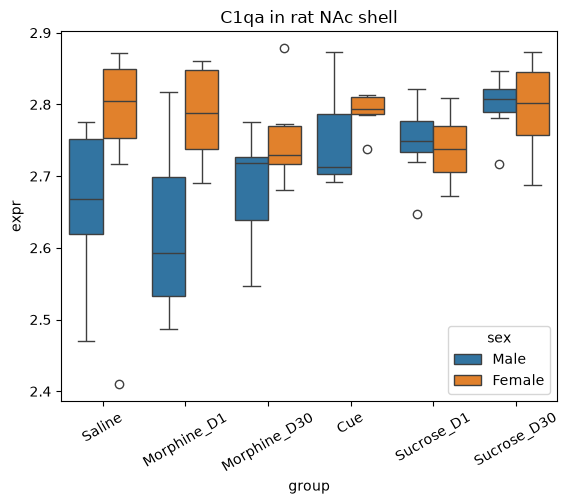

In [8]:
rat_log = np.log2(rat.counts + 1)
gene = "C1qa"
sns.boxplot(data=rat.meta.assign(expr=rat_log.loc[gene]), x="group", y="expr", hue="sex")
plt.xticks(rotation=30)
plt.title(f"{gene} in rat NAc shell")

In [9]:
human.meta.groupby(["region", "diagnosis"], observed=True)[["age", "pmi"]].describe().round(1)

age                                             pmi        \
                  count  mean   std   min   25%   50%   75%   max count  mean   
region  diagnosis                                                               
Caudate Control    20.0  34.8  12.6  18.0  20.8  36.5  45.8  52.0  20.0  17.3   
        CUD        25.0  36.9   7.8  19.0  33.0  38.0  41.0  49.0  25.0  18.0   
NAc     Control    19.0  34.2  12.6  18.0  20.5  34.0  45.0  52.0  19.0  16.9   
        CUD        25.0  36.9   7.8  19.0  33.0  38.0  41.0  49.0  25.0  18.0   

                                                     
                   std  min   25%   50%   75%   max  
region  diagnosis                                    
Caudate Control    6.9  8.0  11.0  17.2  24.0  32.1  
        CUD        6.3  7.0  14.0  18.0  23.0  32.0  
NAc     Control    6.8  8.0  11.0  16.3  22.2  32.1  
        CUD        6.3  7.0  14.0  18.0  23.0  32.0

<Axes: xlabel='age', ylabel='C1QA'>

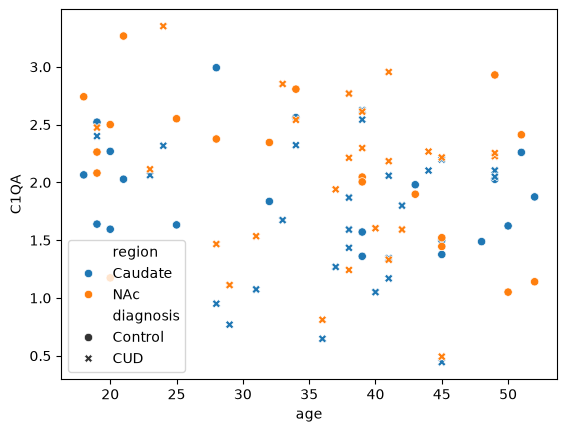

In [10]:
cpm = human.counts / human.counts.sum() * 1e6
df = human.meta.assign(C1QA=np.log2(cpm.loc["ENSG00000173372"] + 1))
sns.scatterplot(data=df, x="age", y="C1QA", hue="region", style="diagnosis")

In [11]:
heroin.meta[["region", "walker_region"]].drop_duplicates()

,region,walker_region
sample,,
P-52,PFC,PFC
S-118,dStri,Cpu
N-79,NAc,NAc
H-243,vHPC,Hipp
V-267,VTA,VTA
3-13,BLA,BLA


#### Fix: inferred donor ID for human data (GSE214267)

**Problem**
- GEO metadata has no donor ID, so Caudate and NAc samples from the same person were treated as independent.
- CUD age and PMI statistics were identical in both regions, which revealed a paired design.

**Change**
- Added `infer_subject_ids()` to `human_cud.py`, creating a `subject_id` column (S01–S45) in `meta`.
- Samples sharing diagnosis, age, PMI and race are grouped as one donor. **This ID is inferred, not provided by GEO.**
- Result: 45 donors (20 Control, 25 CUD); 44 have both regions and 1 has Caudate only.
- Safeguards: error if a donor has two samples from the same region; warning if the result is not 45 donors with 44 pairs.

**Implication**
- The human CUD vs control analysis can use a mixed model with donor as a random effect.
- Remaining caveats:
  - Control ages are more spread out than CUD ages, so the human CUD vs control analysis must adjust for age.
  - In the rat morphine/sucrose data, sex and reinforcer coincide with file batch, so the rat analysis compares groups only within the same file.

In [5]:
human = load_human_cud(cfg)
human.meta[["subject_id", "region", "diagnosis", "age", "pmi"]].head()

,subject_id,region,diagnosis,age,pmi
sample,,,,,
GSM6602739,S35,Caudate,Control,34.0,11.5
GSM6602740,S37,Caudate,Control,39.0,24.0
GSM6602741,S31,Caudate,Control,21.0,18.5
GSM6602742,S36,Caudate,Control,39.0,11.0
GSM6602743,S30,Caudate,Control,20.0,9.0


In [6]:
pairs = human.meta.pivot(index="subject_id", columns="region", values="well")
pairs.head(), pairs.notna().sum()

(region     Caudate  NAc
 subject_id             
 S01             B6  G11
 S02             A6  F11
 S03             B5  G10
 S04             C4   H9
 S05             F5  C11,
 region
 Caudate    45
 NAc        44
 dtype: int64)

In [7]:
pairs[pairs["NAc"].isna()]

region,Caudate,NAc
subject_id,,
S41,C2,NaN


Text(0.5, 1.0, 'C1QA: same donor, two regions (Spearman r = 0.69)')

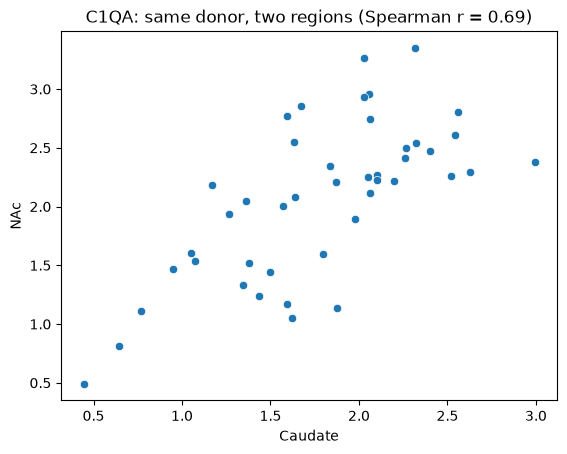

In [8]:
cpm = human.counts / human.counts.sum() * 1e6
c1qa = np.log2(cpm.loc["ENSG00000173372"] + 1).rename("C1QA")
wide = (human.meta.assign(C1QA=c1qa)
        .pivot(index="subject_id", columns="region", values="C1QA").dropna())

sns.scatterplot(data=wide, x="Caudate", y="NAc")
plt.title(f"C1QA: same donor, two regions (Spearman r = {wide.corr(method='spearman').iloc[0, 1]:.2f})")